# Removing ambient / contamination RNA from droplet scRNA-seq

Every droplet-based single-cell library is contaminated with **ambient
RNA** — cell-free transcripts that leak out of stressed or lysed cells
into the suspension and get co-encapsulated with real cells. This
"soup" is captured and sequenced alongside each cell's native
transcriptome, so **every cell barcode carries a background of
transcripts it never expressed**.

Left uncorrected, ambient RNA is not harmless noise:

- it **inflates marker genes** in cell types that never expressed them —
  a T-cell barcode picks up haemoglobin from lysed erythrocytes, a
  neuron picks up a glial marker;
- it **distorts differential expression** and cluster annotation, and
  produces phantom "doublet-like" or "low-quality" populations;
- it scales with the soup concentration, so it is worst exactly in the
  samples that are hardest to dissociate (tumours, brain, frozen
  tissue).

Several methods estimate and subtract this background:

- **SoupX** (Young & Behjati, *GigaScience* 2020) — reads the soup
  profile out of the **empty droplets** and subtracts a per-cell
  fraction.
- **DecontX** (Yang *et al.*, *Genome Biology* 2020) — a variational-EM
  model that needs a **clustered** matrix, no empty droplets required.
- **FastCAR** (Berg *et al.* 2023) — deterministic per-gene subtraction
  from the empty-droplet ambient profile.
- **scCDC** (Wang *et al.* 2024) — corrects **only** the
  Global-Contamination-causing Genes, deliberately conservative.
- **CellBender** (Fleming *et al.*, *Nature Methods* 2023) — a deep
  generative model; best overall in benchmarks but GPU-heavy.

`ov.pp.ambient` threads the four native, pip-installable backends
(`pysoupx`, `pydecontx`, `pyfastcar`, `pysccdc`) behind a single
`remove_ambient` dispatcher, and adds diagnostics that audit the
correction.

**Where this step belongs.** Ambient removal operates on **raw
counts**, so it runs **after cell calling** (you need the filtered
cells, and for SoupX / FastCAR also the empty droplets) and **before
normalization, HVG selection and clustering**. In this tutorial we
cluster first only because DecontX / scCDC need cluster labels — in a
real pipeline you would do a quick preliminary clustering, decontaminate,
then re-run the full downstream analysis on the cleaned counts.

## 1. Load a real raw 10x dataset

`ov.datasets.pbmc_raw_10x()` downloads the 10x Genomics **`pbmc_1k_v3`**
dataset (peripheral-blood mononuclear cells, Chromium 3' v3, processed
with Cell Ranger 3.0.0). With `raw_droplets=True` it returns **two**
AnnData objects:

- `cells` — the **filtered** real cells (1,222 cells x 15,300 genes,
  raw UMI counts in `.X`);
- `raw` — the **raw unfiltered** droplet matrix (13,222 droplets =
  the 1,222 cells **plus 12,000 empty droplets**).

SoupX and FastCAR build their soup profile from those empty droplets, so
they need the `raw` object; DecontX and scCDC work from the filtered,
clustered cells alone.

In [1]:
import omicverse as ov
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt

ov.plot_set()

/scratch/users/steorra/env/omicdev/lib/python3.10/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/scratch/users/steorra/env/omicdev/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)


🔬 Starting plot initialization...
🧬 Detecting GPU devices…
🚫 No GPU devices found (CUDA/MPS/ROCm/XPU)

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.2.1rc1   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



In [2]:
cells, raw = ov.datasets.pbmc_raw_10x(raw_droplets=True)
cells, raw

🔍 Downloading data to ./data/pbmc_raw_10x_cells.h5ad
⚠️ File ./data/pbmc_raw_10x_cells.h5ad already exists
🔍 Downloading data to ./data/pbmc_raw_10x_raw.h5ad
⚠️ File ./data/pbmc_raw_10x_raw.h5ad already exists


(AnnData object with n_obs × n_vars = 1222 × 15300
     obs: 'n_counts', 'n_genes'
     var: 'gene_ids', 'feature_types', 'genome'
     uns: 'dataset',
 AnnData object with n_obs × n_vars = 13222 × 15300
     obs: 'droplet_type', 'n_counts'
     var: 'gene_ids', 'feature_types', 'genome'
     uns: 'dataset')

In [3]:
# the raw matrix mixes real cells and empty droplets
raw.obs['droplet_type'].value_counts()

droplet_type
empty    12000
cell      1222
Name: count, dtype: int64

### The barcode-rank plot

The classic way to *see* the soup is the **barcode-rank plot**: total
UMIs per droplet, sorted from highest to lowest on a log-log scale. Real
cells sit on the high plateau; the long low tail is empty droplets that
contain **only ambient RNA** — that tail is the soup profile SoupX and
FastCAR estimate from.

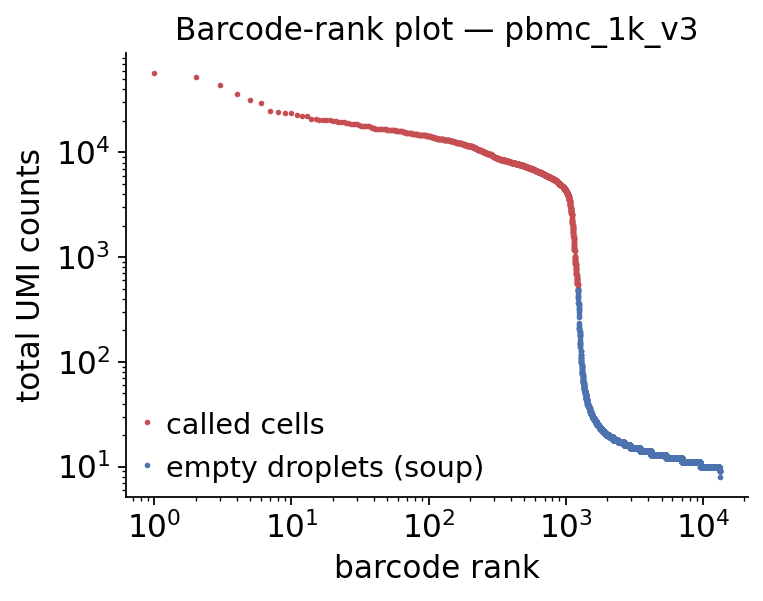

In [4]:
counts = np.asarray(raw.X.sum(axis=1)).ravel()
order = np.argsort(counts)[::-1]
is_cell = (raw.obs['droplet_type'] == 'cell').to_numpy()[order]

fig, ax = plt.subplots(figsize=(5, 4))
rank = np.arange(1, len(counts) + 1)
ax.loglog(rank[is_cell], counts[order][is_cell], '.', ms=3,
          color='#C44E52', label='called cells')
ax.loglog(rank[~is_cell], counts[order][~is_cell], '.', ms=3,
          color='#4C72B0', label='empty droplets (soup)')
ax.set_xlabel('barcode rank')
ax.set_ylabel('total UMI counts')
ax.set_title('Barcode-rank plot — pbmc_1k_v3')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 2. A quick clustering

DecontX and scCDC need cluster labels, and SoupX uses them to
auto-estimate the contamination fraction. We run a standard omicverse
preprocessing + Leiden pipeline on a **working copy**, then transfer the
labels and the UMAP back onto the raw-count `cells` object — ambient
removal must operate on **raw counts across all genes**, not on the
log-normalised HVG subset.

In [5]:
work = cells.copy()
work = ov.pp.preprocess(work, mode='shiftlog|pearson', n_HVGs=2000)
work.raw = work
work = work[:, work.var.highly_variable_features].copy()

🔍 [2026-05-22 00:17:46] Running preprocessing in 'cpu' mode...
Begin robust gene identification
    After filtration, 15300/15300 genes are kept.
    Among 15300 genes, 15300 genes are robust.
✅ Robust gene identification completed successfully.
Begin size normalization: shiftlog and HVGs selection pearson

🔍 Count Normalization:
   Target sum: 500000.0
   Exclude highly expressed: True
   Max fraction threshold: 0.2
   ⚠️ Excluding 5 highly-expressed genes from normalization computation
   Excluded genes: ['IGKC', 'HBB', 'MALAT1', 'MT-CO1', 'MT-CO3']

✅ Count Normalization Completed Successfully!
   ✓ Processed: 1,222 cells × 15,300 genes
   ✓ Runtime: 0.07s

🔍 Highly Variable Genes Selection (Experimental):
   Method: pearson_residuals
   Target genes: 2,000
   Theta (overdispersion): 100



✅ Experimental HVG Selection Completed Successfully!
   ✓ Selected: 2,000 highly variable genes out of 15,300 total (13.1%)
   ✓ Results added to AnnData object:
     • 'highly_variable': Boolean vector (adata.var)
     • 'highly_variable_rank': Float vector (adata.var)
     • 'highly_variable_nbatches': Int vector (adata.var)
     • 'highly_variable_intersection': Boolean vector (adata.var)
     • 'means': Float vector (adata.var)
     • 'variances': Float vector (adata.var)
     • 'residual_variances': Float vector (adata.var)
    Time to analyze data in cpu: 1.31 seconds.
✅ Preprocessing completed successfully.
    Added:
        'highly_variable_features', boolean vector (adata.var)
        'means', float vector (adata.var)
        'variances', float vector (adata.var)
        'residual_variances', float vector (adata.var)
        'counts', raw counts layer (adata.layers)
    End of size normalization: shiftlog and HVGs selection pearson

╭─ SUMMARY: preprocess ───────────────────

In [6]:
ov.pp.scale(work)
ov.pp.pca(work, layer='scaled', n_pcs=30)
ov.pp.neighbors(work, n_neighbors=15, n_pcs=30, use_rep='scaled|original|X_pca')
ov.pp.leiden(work, resolution=1.0)
ov.pp.umap(work)


╭─ SUMMARY: scale ───────────────────────────────────────────────────╮
│  Duration: 0.0259s                                                 │
│  Shape:    1,222 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● LAYERS │ ✚ scaled (array, 1222x2000)                            │
│                                                                    │
╰────────────────────────────────────────────────────────────────────╯
computing PCA🔍
    with n_comps=30
   🖥️ Using sklearn PCA for CPU computation
   🖥️ sklearn PCA backend: CPU computation
   📊 PCA input data type: ArrayView, shape: (1222, 2000), dtype: float64


   🔧 PCA solver used: covariance_eigh
    finished✅ (5.87s)

╭─ SUMMARY: pca ─────────────────────────────────────────────────────╮
│  Duration: 5.8701s                                                 │
│  Shape:    1,222 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ pca                                                  │
│           │ └─ params: {'zero_center': True, 'use_highly_variable': Tr...│
│           │ ✚ scaled|original|cum_sum_eigenvalues                  │
│           │ ✚ scaled|original|pca_var_ratios                       │
│                                                                    │
│  ● OBSM   │ ✚ X_pca (array, 1222x30)                               │
│           │ ✚ scaled|original|X_pca (array, 1222x30)               │
│         

   🔍 Computing connectivity matrix...
   💡 Using UMAP-style connectivity


   ✓ Graph is fully connected

✅ KNN Graph Construction Completed Successfully!
   ✓ Processed: 1,222 cells with 15 neighbors each
   ✓ Results added to AnnData object:
     • 'neighbors': Neighbors metadata (adata.uns)
     • 'distances': Distance matrix (adata.obsp)
     • 'connectivities': Connectivity matrix (adata.obsp)

╭─ SUMMARY: neighbors ───────────────────────────────────────────────╮
│  Duration: 11.3594s                                                │
│  Shape:    1,222 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ neighbors                                            │
│           │ └─ params: {'n_neighbors': 15, 'method': 'umap', 'random_s...│
│                                                                    │
│  ● OBSP   │ ✚ connectivit


✅ UMAP Dimensionality Reduction Completed Successfully!
   ✓ Embedding shape: 1,222 cells × 2 dimensions
   ✓ Results added to AnnData object:
     • 'X_umap': UMAP coordinates (adata.obsm)
     • 'umap': UMAP parameters (adata.uns)
✅ UMAP completed successfully.

╭─ SUMMARY: umap ────────────────────────────────────────────────────╮
│  Duration: 0.794s                                                  │
│  Shape:    1,222 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ umap                                                 │
│           │ └─ params: {'a': np.float64(0.5830300203414425), 'b': np.f...│
│                                                                    │
│  ● OBSM   │ ✚ X_umap (array, 1222x2)                               │
│                 

In [7]:
# transfer the cluster labels + embedding onto the raw-count AnnData
cells.obs['leiden'] = work.obs['leiden'].values
cells.obsm['X_umap'] = work.obsm['X_umap']
cells.obs['leiden'].value_counts()

leiden
0     224
1     182
2     125
3     122
4     108
5      72
6      69
7      64
8      63
9      57
10     54
11     47
12     35
Name: count, dtype: int64

## 3. Run `remove_ambient` with each native method

`ov.pp.ambient.remove_ambient` is a single `method=` dispatcher. It
writes the decontaminated counts back into `.X`, keeps the original
counts in `layers['ambient_raw']`, stores the per-cell contamination
fraction in `obs['ambient_contamination']`, and records method metadata
in `uns['ambient']`.

- **SoupX / FastCAR** need the raw unfiltered matrix — pass `raw=`.
- **DecontX / scCDC** need cluster labels — pass `cluster_key=`.

We run all four on independent copies so we can compare them.

In [8]:
ad_soupx = cells.copy()
ov.pp.ambient.remove_ambient(ad_soupx, method='soupx', raw=raw,
                             cluster_key='leiden', verbose=True)

773 genes passed tf-idf cut-off and 103 soup quantile filter. Taking the top 100.
Using 952 independent estimates of rho.


Estimated global rho of 0.01


[ov.pp.ambient] method=soupx  mean contamination=0.0100  genes corrected=15300


AnnData object with n_obs × n_vars = 1222 × 15300
    obs: 'n_counts', 'n_genes', 'leiden', 'ambient_contamination'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'dataset', 'ambient'
    obsm: 'X_umap'
    layers: 'ambient_raw'

In [9]:
ad_decontx = cells.copy()
ov.pp.ambient.remove_ambient(ad_decontx, method='decontx',
                             cluster_key='leiden', verbose=True)

DecontX: analysing batch 'all_cells' (1222 cells)


  iter 10 | converge: 0.03146


  iter 20 | converge: 0.0201


  iter 30 | converge: 0.009111


  iter 40 | converge: 0.004174


  iter 50 | converge: 0.002953


... (4 outputs left out)

  iter 100 | converge: 0.001244


  iter 110 | converge: 0.001005
  iter 111 | converge: 0.001


[ov.pp.ambient] method=decontx  mean contamination=0.0856  genes corrected=15300


AnnData object with n_obs × n_vars = 1222 × 15300
    obs: 'n_counts', 'n_genes', 'leiden', 'ambient_contamination'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'dataset', 'ambient'
    obsm: 'X_umap'
    layers: 'ambient_raw'

In [10]:
ad_fastcar = cells.copy()
ov.pp.ambient.remove_ambient(ad_fastcar, method='fastcar', raw=raw,
                             verbose=True)

[ov.pp.ambient] method=fastcar  mean contamination=0.0941  genes corrected=247


AnnData object with n_obs × n_vars = 1222 × 15300
    obs: 'n_counts', 'n_genes', 'leiden', 'ambient_contamination'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'dataset', 'ambient'
    obsm: 'X_umap'
    layers: 'ambient_raw'

In [11]:
ad_sccdc = cells.copy()
ov.pp.ambient.remove_ambient(ad_sccdc, method='sccdc',
                             cluster_key='leiden', verbose=True)

[ov.pp.ambient] method=sccdc  mean contamination=0.1317  genes corrected=59


AnnData object with n_obs × n_vars = 1222 × 15300
    obs: 'n_counts', 'n_genes', 'leiden', 'ambient_contamination'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'dataset', 'ambient'
    obsm: 'X_umap'
    layers: 'ambient_raw'

### Per-cell contamination fraction

Each run populates `obs['ambient_contamination']`. The four methods make
different modelling assumptions, so they will *not* agree on a single
number — that disagreement is itself informative, and the diagnostics
below let us judge the corrections rather than trust them blindly.

In [12]:
import pandas as pd
summary = pd.DataFrame({
    'soupx':   [ad_soupx.uns['ambient']['contamination_fraction']],
    'decontx': [ad_decontx.uns['ambient']['contamination_fraction']],
    'fastcar': [ad_fastcar.uns['ambient']['contamination_fraction']],
    'sccdc':   [ad_sccdc.uns['ambient']['contamination_fraction']],
}, index=['mean contamination fraction'])
summary.T

,mean contamination fraction
soupx,0.010000
decontx,0.085641
fastcar,0.094148
sccdc,0.131743


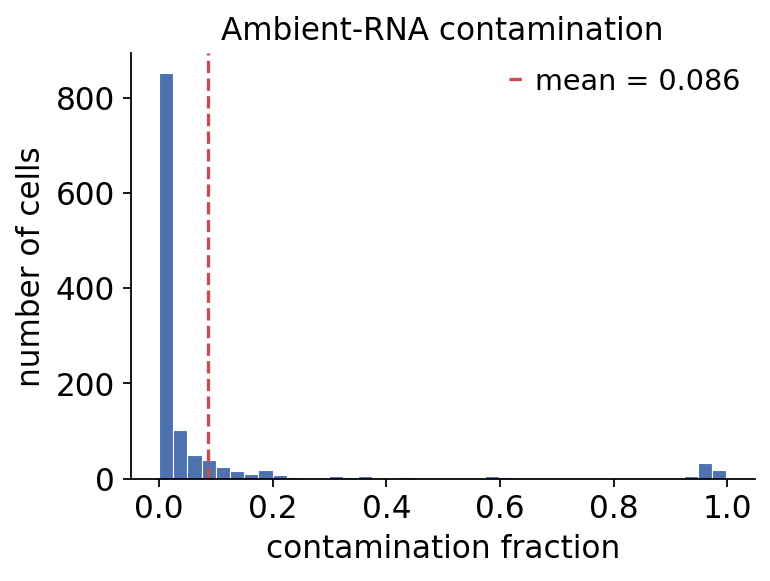

In [13]:
# distribution of the per-cell contamination fraction (DecontX run)
ov.pp.ambient.plot_contamination(ad_decontx)
plt.show()

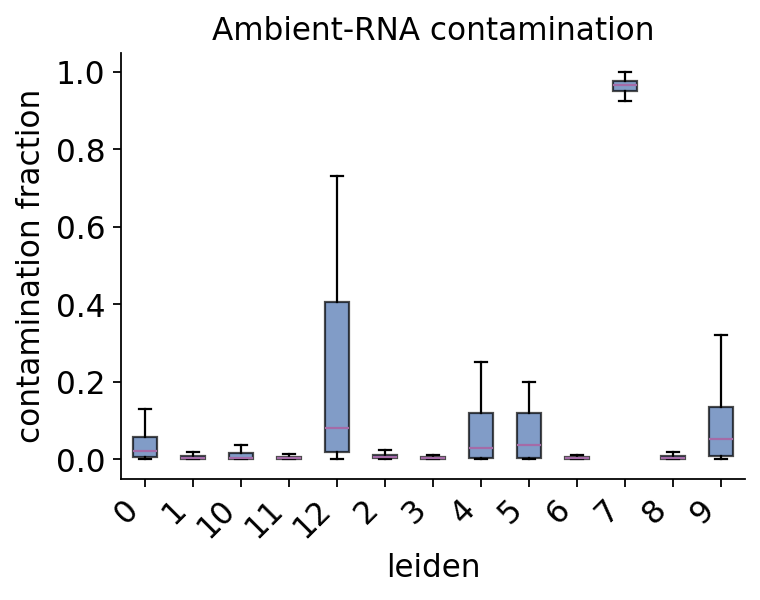

In [14]:
# contamination tends to track cell type — show it per Leiden cluster
ov.pp.ambient.plot_contamination(ad_decontx, groupby='leiden')
plt.show()

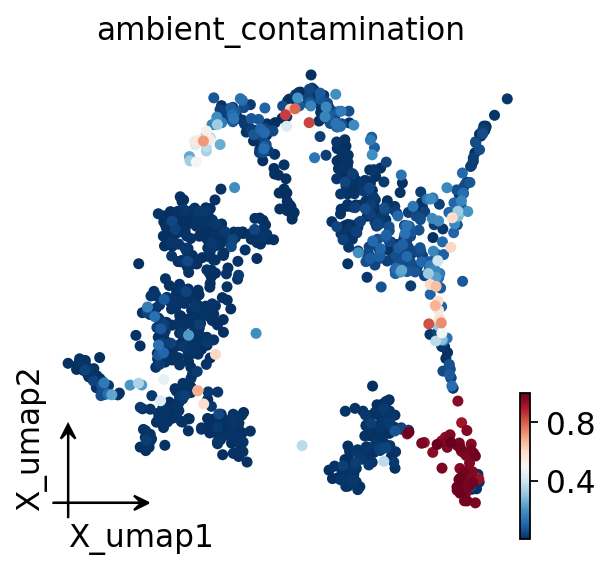

In [15]:
# overlay the contamination fraction on the UMAP
ov.pl.embedding(ad_decontx, basis='X_umap', color='ambient_contamination',
                frameon='small', show=False)
plt.show()

### Corrected vs raw counts

The decontaminated counts are now in `.X`; the originals are preserved
in `layers['ambient_raw']`. The total UMIs only ever go **down** —
ambient removal subtracts, it never adds.

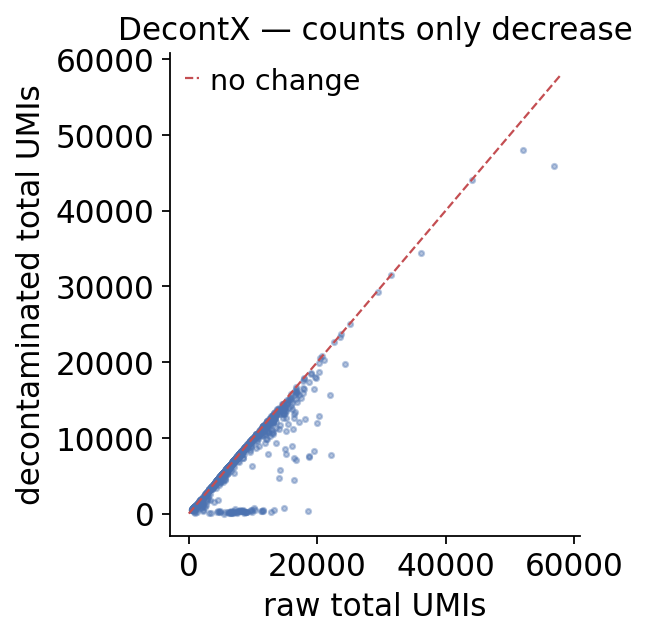

In [16]:
raw_tot = np.asarray(ad_decontx.layers['ambient_raw'].sum(axis=1)).ravel()
cor_tot = np.asarray(ad_decontx.X.sum(axis=1)).ravel()

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.scatter(raw_tot, cor_tot, s=5, alpha=0.4, color='#4C72B0')
lim = [0, raw_tot.max() * 1.02]
ax.plot(lim, lim, '--', color='#C44E52', lw=1, label='no change')
ax.set_xlabel('raw total UMIs')
ax.set_ylabel('decontaminated total UMIs')
ax.set_title('DecontX — counts only decrease')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 4. Diagnostics

`ov.pp.ambient` ships read-only audits that check whether a correction
behaved sensibly — they do not modify the data.

### 4.1 Negative-marker check

A correct decontamination should drive a **cell-type-specific marker**
back toward zero in the cell types that biologically do **not** express
it. Haemoglobin **HBB** is the textbook example: it is hugely expressed
in erythrocytes/platelet contamination and leaks into every other
barcode as soup. `ambient_negative_marker_check` compares the raw vs
corrected mean of HBB across cell types and reports the fold reduction
in the cell types that should be HBB-negative.

In [17]:
hbb = ov.pp.ambient.ambient_negative_marker_check(
    ad_decontx, 'HBB', 'leiden')
hbb[['n_cells', 'raw_mean', 'corrected_mean', 'fold_reduction']].round(3)

,n_cells,raw_mean,corrected_mean,fold_reduction
celltype,,,,
0,224,0.000,0.000,inf
2,125,0.000,0.000,inf
8,63,0.000,0.000,inf
1,182,0.049,0.047,1.057000e+00
7,64,0.016,0.000,7.470206e+16
11,47,0.000,0.000,inf
6,69,0.000,0.000,inf
9,57,0.000,0.000,inf
4,108,4.056,4.056,1.000000e+00


In [18]:
# the aggregate over the HBB-negative cell types
hbb.attrs['summary']

{'marker': 'HBB',
 'positive_celltypes': ['4'],
 'n_negative_celltypes': 12,
 'neg_raw_mean': 0.0054229625190297765,
 'neg_corrected_mean': 0.0038977974782859297,
 'neg_fold_reduction': 1.3912889392638592}

The positive cell type (highest raw HBB — the erythroid/platelet
cluster) keeps its HBB, while the HBB-negative cell types see their
residual haemoglobin signal pushed down. That is exactly the behaviour
ambient removal should produce: soup stripped, biology preserved.

### 4.2 Count-integrity check

A trustworthy correction only **subtracts**: no matrix entry may grow,
and only the contaminated genes should change at all.
`count_integrity_check` verifies this against the 2026 ambient-RNA
benchmark count-integrity criterion.

In [19]:
integ = ov.pp.ambient.count_integrity_check(
    ad_decontx.layers['ambient_raw'], ad_decontx.X)
integ

{'passed': True,
 'n_entries': 18696600,
 'n_increased': 0,
 'max_increase': 0.0,
 'n_unchanged': 16203657,
 'frac_unchanged': 0.8666632970700555,
 'frac_changed': 0.13333670292994448,
 'total_raw': 9230791.0,
 'total_corrected': 8344633.546892991,
 'total_removed': 886157.4531070087,
 'removed_fraction': 0.09600016435287168}

### 4.3 Contamination report

`contamination_report` reads the metadata `remove_ambient` wrote into
`obs` / `uns` and returns a compact one-row summary per method.

In [20]:
report = pd.concat([
    ov.pp.ambient.contamination_report(ad_soupx),
    ov.pp.ambient.contamination_report(ad_decontx),
    ov.pp.ambient.contamination_report(ad_fastcar),
    ov.pp.ambient.contamination_report(ad_sccdc),
], ignore_index=True)
report

,method,n_cells,n_genes,genes_corrected,mean_contamination,median_contamination,min_contamination,max_contamination,integrity_passed,removed_fraction,frac_genes_changed
0,soupx,1222,15300,15300,0.010000,0.010000,0.010000,0.010000,True,0.010000,0.126952
1,decontx,1222,15300,15300,0.085641,0.007672,0.000039,0.998265,True,0.096000,0.133337
2,fastcar,1222,15300,247,0.094148,0.083521,0.009843,0.382253,True,0.070733,0.013277
3,sccdc,1222,15300,59,0.131743,0.103346,0.001969,0.802548,True,0.094104,0.003494


## 5. Ground-truth validation on a species-mixing dataset

On real PBMCs we have no ground truth for the soup — we can only check
that the correction behaves sensibly. The **human-mouse species-mixing
("barnyard") experiment** removes that ambiguity.

`ov.datasets.hgmm_mixture()` loads the 10x **`hgmm_1k_v3`** dataset: a
1:1 mix of human (HEK293T) and mouse (NIH3T3) cells, sequenced against a
combined `hg19 + mm10` reference. Because the two species share no
genes, **any transcript mapped to the *other* species inside a cell is
unambiguous ambient contamination**. The per-cell minor-species read
fraction is therefore a direct, label-free measure of soup — and a real
correction must reduce it.

In [21]:
hg_cells, hg_raw = ov.datasets.hgmm_mixture(raw_droplets=True)
hg_cells.obs['species'].value_counts()

🔍 Downloading data to ./data/hgmm_mixture_cells.h5ad
⚠️ File ./data/hgmm_mixture_cells.h5ad already exists
🔍 Downloading data to ./data/hgmm_mixture_raw.h5ad
⚠️ File ./data/hgmm_mixture_raw.h5ad already exists


species
mouse    544
human    495
mixed      7
Name: count, dtype: int64

We split the genes by genome (`hg19` vs `mm10`) and define the
**cross-species fraction** of a count matrix as the minor-species share
of each cell's reads — `min(human_frac, mouse_frac)`. With the genome
masks fixed, this is a short vectorised expression we reuse for the raw
matrix and for each decontaminated matrix.

In [22]:
# genome masks — fixed once, the soup measurement reuses them
genome = hg_cells.var['genome'].to_numpy()
hg_mask = genome == 'hg19'
mm_mask = genome == 'mm10'
print(f'{hg_mask.sum()} human (hg19) genes, {mm_mask.sum()} mouse (mm10) genes')

16122 human (hg19) genes, 13862 mouse (mm10) genes


In [23]:
# ground-truth contamination of the RAW counts: minor-species read fraction
hg_umi = np.asarray(hg_cells.X[:, hg_mask].sum(axis=1)).ravel()
mm_umi = np.asarray(hg_cells.X[:, mm_mask].sum(axis=1)).ravel()
hg_frac = hg_umi / np.maximum(hg_umi + mm_umi, 1)
gt_raw = np.minimum(hg_frac, 1.0 - hg_frac)
print(f'ground-truth mean cross-species fraction: {gt_raw.mean():.4f}')
print(f'                            median:       {np.median(gt_raw):.4f}')

ground-truth mean cross-species fraction: 0.0075
                            median:       0.0045


Roughly **0.75 %** of every cell's reads come from the wrong species —
that is the ambient contamination, measured without any model. Now we
cluster the cells (the two species form cleanly separated clusters),
run each backend, and recompute the cross-species fraction from the
**decontaminated** counts.

In [24]:
hg_work = hg_cells.copy()
hg_work = ov.pp.preprocess(hg_work, mode='shiftlog|pearson', n_HVGs=2000)
hg_work.raw = hg_work
hg_work = hg_work[:, hg_work.var.highly_variable_features].copy()
ov.pp.scale(hg_work)
ov.pp.pca(hg_work, layer='scaled', n_pcs=30)
ov.pp.neighbors(hg_work, n_neighbors=15, n_pcs=30,
                use_rep='scaled|original|X_pca')
ov.pp.leiden(hg_work, resolution=0.5)
hg_cells.obs['leiden'] = hg_work.obs['leiden'].values

🔍 [2026-05-22 00:18:46] Running preprocessing in 'cpu' mode...
Begin robust gene identification


    After filtration, 29984/29984 genes are kept.
    Among 29984 genes, 29984 genes are robust.
✅ Robust gene identification completed successfully.
Begin size normalization: shiftlog and HVGs selection pearson



🔍 Count Normalization:
   Target sum: 500000.0
   Exclude highly expressed: True
   Max fraction threshold: 0.2


   ⚠️ Excluding 4 highly-expressed genes from normalization computation
   Excluded genes: ['hg19_MT-CO2', 'mm10_mt-Nd2', 'mm10_mt-Nd4', 'mm10_mt-Cytb']

✅ Count Normalization Completed Successfully!
   ✓ Processed: 1,046 cells × 29,984 genes
   ✓ Runtime: 0.11s

🔍 Highly Variable Genes Selection (Experimental):
   Method: pearson_residuals
   Target genes: 2,000
   Theta (overdispersion): 100



✅ Experimental HVG Selection Completed Successfully!
   ✓ Selected: 2,000 highly variable genes out of 29,984 total (6.7%)
   ✓ Results added to AnnData object:
     • 'highly_variable': Boolean vector (adata.var)
     • 'highly_variable_rank': Float vector (adata.var)
     • 'highly_variable_nbatches': Int vector (adata.var)
     • 'highly_variable_intersection': Boolean vector (adata.var)
     • 'means': Float vector (adata.var)
     • 'variances': Float vector (adata.var)
     • 'residual_variances': Float vector (adata.var)
    Time to analyze data in cpu: 0.97 seconds.
✅ Preprocessing completed successfully.
    Added:
        'highly_variable_features', boolean vector (adata.var)
        'means', float vector (adata.var)
        'variances', float vector (adata.var)
        'residual_variances', float vector (adata.var)
        'counts', raw counts layer (adata.layers)
    End of size normalization: shiftlog and HVGs selection pearson

╭─ SUMMARY: preprocess ────────────────────

   🔧 PCA solver used: covariance_eigh
    finished✅ (1.94s)

╭─ SUMMARY: pca ─────────────────────────────────────────────────────╮
│  Duration: 1.9419s                                                 │
│  Shape:    1,046 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ pca                                                  │
│           │ └─ params: {'zero_center': True, 'use_highly_variable': Tr...│
│           │ ✚ scaled|original|cum_sum_eigenvalues                  │
│           │ ✚ scaled|original|pca_var_ratios                       │
│                                                                    │
│  ● OBSM   │ ✚ X_pca (array, 1046x30)                               │
│           │ ✚ scaled|original|X_pca (array, 1046x30)               │
│         

   ✓ Graph is fully connected

✅ KNN Graph Construction Completed Successfully!
   ✓ Processed: 1,046 cells with 15 neighbors each
   ✓ Results added to AnnData object:
     • 'neighbors': Neighbors metadata (adata.uns)
     • 'distances': Distance matrix (adata.obsp)
     • 'connectivities': Connectivity matrix (adata.obsp)

╭─ SUMMARY: neighbors ───────────────────────────────────────────────╮
│  Duration: 0.2066s                                                 │
│  Shape:    1,046 x 2,000 (Unchanged)                               │
│                                                                    │
│  CHANGES DETECTED                                                  │
│  ────────────────                                                  │
│  ● UNS    │ ✚ neighbors                                            │
│           │ └─ params: {'n_neighbors': 15, 'method': 'umap', 'random_s...│
│                                                                    │
│  ● OBSP   │ ✚ connectivit

In [25]:
# decontaminate with each native method and measure the residual soup
gt = {'raw (no correction)': gt_raw.mean()}
for method in ['soupx', 'decontx', 'fastcar', 'sccdc']:
    a = hg_cells.copy()
    if method in ('soupx', 'fastcar'):
        ov.pp.ambient.remove_ambient(a, method=method, raw=hg_raw,
                                     cluster_key='leiden')
    else:
        ov.pp.ambient.remove_ambient(a, method=method,
                                     cluster_key='leiden')
    hg_c = np.asarray(a.X[:, hg_mask].sum(axis=1)).ravel()
    mm_c = np.asarray(a.X[:, mm_mask].sum(axis=1)).ravel()
    f = hg_c / np.maximum(hg_c + mm_c, 1)
    gt[method] = float(np.minimum(f, 1.0 - f).mean())

gt_df = pd.DataFrame({'mean cross-species fraction': gt})
gt_df['reduction vs raw'] = 1.0 - gt_df['mean cross-species fraction'] / gt['raw (no correction)']
gt_df.round(4)

,mean cross-species fraction,reduction vs raw
raw (no correction),0.0075,0.0000
soupx,0.0042,0.4452
decontx,0.0047,0.3797
fastcar,0.0042,0.4346
sccdc,0.0074,0.0181


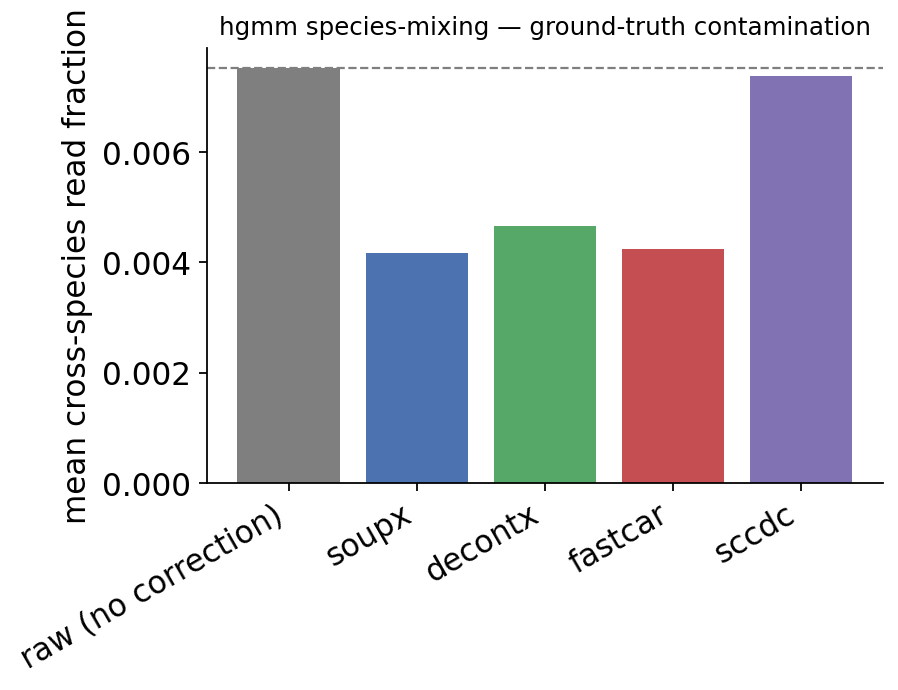

In [26]:
fig, ax = plt.subplots(figsize=(5.5, 4.2), constrained_layout=True)
colors = ["#7f7f7f", "#4C72B0", "#55A868", "#C44E52", "#8172B3"]
ax.bar(gt_df.index, gt_df["mean cross-species fraction"], color=colors)
ax.axhline(gt["raw (no correction)"], ls="--", lw=1, color="#7f7f7f")
ax.set_ylabel("mean cross-species read fraction")
ax.set_title("hgmm species-mixing — ground-truth contamination", fontsize=11)
for tick in ax.get_xticklabels():
    tick.set_rotation(30)
    tick.set_ha("right")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

This is the real test: the cross-species read fraction is a quantity no
method can see during fitting, yet every backend **reduces** it. The
empty-droplet methods (SoupX, FastCAR) and the EM model (DecontX) all
strip a substantial share of the wrong-species reads; scCDC, which by
design only touches Global-Contamination-causing Genes, moves it least —
the expected behaviour of a deliberately conservative method.

## 6. Choosing a method

The four native backends — plus the deep-learning options — make
different trade-offs. The research consensus, and the behaviour seen
above:

| Method | Needs | Strengths | Watch out for |
|---|---|---|---|
| **SoupX** | raw matrix + empty droplets; clusters for auto-rho | gentle, interpretable, fast; reads the soup directly from empty droplets | conservative — under-corrects clean datasets |
| **DecontX** | filtered, clustered matrix | no empty droplets required; per-cell variational estimate | can over-correct if clustering is poor |
| **FastCAR** | raw matrix + empty droplets | deterministic per-gene subtraction; very fast | tuned by hard cutoffs (`empty_droplet_cutoff`) |
| **scCDC** | filtered, clustered matrix | anti-over-correction — only fixes contamination-causing genes | corrects few genes; leaves most soup if it is diffuse |
| **CellBender** | raw 10x h5 (GPU) | best overall in benchmarks; jointly calls cells + removes background | heavyweight, GPU, run via its own CLI |
| **scAR** | raw matrix (GPU) | deep ambient denoising | heavyweight, GPU |

Practical guidance:

- **Have empty droplets and want a safe default** — SoupX. It rarely
  hurts and is easy to reason about.
- **Only have a filtered matrix** (a public h5ad, no raw droplets) —
  DecontX or scCDC.
- **Worried about over-correction** of biologically real markers —
  scCDC.
- **Compute budget and a GPU** — CellBender generally wins benchmarks,
  but is heavyweight; `ov.pp.ambient` keeps its wrapper thin and points
  you at CellBender's own `remove-background` CLI, then load the result
  with `ov.read`.

Whatever you pick, **audit it**: `ambient_negative_marker_check`,
`count_integrity_check` and — when you have one — a ground-truth signal
like the cross-species fraction. Then continue the normal workflow
(normalize, HVG, cluster, annotate) on the decontaminated `.X`.

## 7. A backend-free estimator for multi-preparation data: `method='envelope'`

The four backends above each rest on an **anchor** that the data have to
provide. SoupX needs *marker genes* that are essentially absent from some
cells, so that every count it sees there must be soup. DecontX needs the
clusters' native profiles to be separable from the soup. FastCAR subtracts a
fixed per-gene amount, which only makes sense when one soup profile
describes every droplet.

A common design breaks these anchors at once: **several preparations
(samples, lanes, dissociations) pooled into one matrix**, each with its own
soup, only a few hundred shallow empty droplets per preparation, and **no
population-private gene**: every gene that carries soup is also expressed,
at some level, by more than one population. SoupX then stops with
`No plausible marker genes found`.

`method='envelope'` (pure NumPy / SciPy / scikit-learn, no extra backend)
is built for exactly that case.

**Principle.** Within one population the contaminated profile is a
two-component mixture,

$$O_c \sim \mathrm{Multinomial}\big(N_c,\ (1-\rho_c)\,p + \rho_c\, b\big),$$

and its likelihood is *invariant* under moving some contamination into the
native profile $p$: a likelihood fit can rank cells by $\rho_c$ but cannot
pin its level. The envelope estimator pins the level with genes that are
almost pure soup readout instead:

1. a **per-preparation soup profile** $b^{(j)}$ from that preparation's
   empty droplets, empirical-Bayes shrunk toward the pooled soup (each
   preparation has few ambient UMIs);
2. **lineages** from a PCA + k-means embedding (or your own `cluster_key`);
3. per lineage × preparation, the ~50 genes with the **lowest
   native-to-soup ratio** (the *lower envelope*). For those genes nearly
   every count is ambient, so observed / expected-ambient counts estimates
   $\rho_c$. The small panel is split into **disjoint** sub-panels whose
   per-cell estimates are medianed, so one rare programme cannot drag the
   answer;
4. mild empirical-Bayes shrinkage of each cell toward its group's pooled
   value, then a global `level_shrink` factor (default 0.75, see 7.5);
5. subtract $b^{(j)}\rho_c N_c$ from each cell, floor at zero and round.

An optional constrained EM (`use_em=True`) then redistributes contamination
across cells using every gene, while keeping the level the envelope fixed.

To judge it we need a ground truth, so we first **simulate** such a dataset
and then return to the real species-mixing data of section 5.
This section is self-contained: it re-imports everything it needs.

In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import omicverse as ov

ov.plot_set()

🔬 Starting plot initialization...
🧬 Detecting GPU devices…
🚫 No GPU devices found (CUDA/MPS/ROCm/XPU)

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.3.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



### 7.1 Simulate three preparations with different soups

* 600 genes, 5 populations, 3 preparations. Populations are unevenly
  distributed across preparations (as with real samples), so each
  preparation's soup, the lysate of *its* cells, has a different profile.
* Every gene has a non-zero baseline in **every** population, and each
  population over-expresses 40 marker genes 20 to 60-fold. There is **no
  population-private gene**.
* The per-cell contamination fraction $\rho_c$ is drawn from a Beta
  distribution (mean ≈ 0.15) **independently of depth**. Native and ambient
  counts are tracked separately, so `true_native` is the answer a perfect
  correction would return.
* Each preparation contributes 400 shallow empty droplets (~30 UMI each).

In [2]:
rng = np.random.default_rng(7)
n_genes, n_pop, n_prep = 600, 5, 3
genes = [f'gene{i:03d}' for i in range(n_genes)]

# native expression profiles: gene baseline x population noise, plus 40 markers each
base = rng.lognormal(0.0, 1.0, n_genes)
native = base * rng.lognormal(0.0, 0.4, (n_pop, n_genes))
for k in range(n_pop):
    markers = rng.choice(n_genes, 40, replace=False)
    native[k, markers] *= rng.uniform(20, 60, 40)
native /= native.sum(1, keepdims=True)

# preparations differ in composition -> different soups
composition = np.array([[0.40, 0.30, 0.15, 0.10, 0.05],
                        [0.05, 0.15, 0.40, 0.30, 0.10],
                        [0.20, 0.05, 0.10, 0.25, 0.40]])
soup = composition @ native * rng.lognormal(0, 0.25, (n_prep, n_genes))
soup /= soup.sum(1, keepdims=True)

cells_per_prep = 1000
obs, X, Xtrue = [], [], []
for j in range(n_prep):
    pop = rng.choice(n_pop, cells_per_prep, p=composition[j])
    depth = rng.lognormal(np.log(2500), 0.5, cells_per_prep).astype(int)
    rho = rng.beta(4, 22, cells_per_prep)              # mean ~0.15
    n_amb = rng.binomial(depth, rho)
    for c in range(cells_per_prep):
        nat = rng.multinomial(depth[c] - n_amb[c], native[pop[c]])
        amb = rng.multinomial(n_amb[c], soup[j])
        X.append(nat + amb)
        Xtrue.append(nat)
        obs.append((f'prep{j}_cell{c:04d}', f'prep{j}', f'pop{pop[c]}',
                    n_amb[c] / depth[c]))
obs = pd.DataFrame(obs, columns=['barcode', 'prep', 'population', 'true_rho']).set_index('barcode')
cells = ad.AnnData(sp.csr_matrix(np.array(X, dtype=np.float32)), obs=obs,
                   var=pd.DataFrame(index=genes))
true_native = np.array(Xtrue, dtype=np.float64)

# the raw droplet matrix of the same runs: the called cells + the empty droplets
empty_X, empty_obs = [], []
for j in range(n_prep):
    for e in range(400):
        n = max(int(rng.lognormal(np.log(30), 0.5)), 1)
        empty_X.append(rng.multinomial(n, soup[j]))
        empty_obs.append((f'prep{j}_empty{e:04d}', f'prep{j}'))
empties = ad.AnnData(sp.csr_matrix(np.array(empty_X, dtype=np.float32)),
                     obs=pd.DataFrame(empty_obs, columns=['barcode', 'prep']).set_index('barcode'),
                     var=pd.DataFrame(index=genes))
raw = ad.concat([cells, empties])
raw.obs['prep'] = list(cells.obs['prep']) + list(empties.obs['prep'])
print(cells)
print(f'raw droplets: {raw.n_obs} ({empties.n_obs} empty)')
print(f"true mean contamination: {cells.obs['true_rho'].mean():.4f}")

AnnData object with n_obs × n_vars = 3000 × 600
    obs: 'prep', 'population', 'true_rho'
raw droplets: 4200 (1200 empty)
true mean contamination: 0.1539


3,000 cells in three preparations, 1,200 empty droplets, and a true mean
contamination of about 15 %. Because we kept the native counts, every method
can be scored on two things: how close its per-cell $\hat\rho_c$ is to the
truth (level and rank), and how much of the L1 distance between the observed
and the true native counts its correction closes ("gap closed": 1 = perfect,
0 = no better than doing nothing, negative = worse than doing nothing).

In [3]:
def score(adata, name):
    """Recovered rho vs truth, and the fraction of the observed-vs-native L1 gap closed."""
    corrected = adata.X.toarray() if sp.issparse(adata.X) else np.asarray(adata.X)
    observed = cells.X.toarray()
    gap_raw = np.abs(observed - true_native).sum()
    gap_cor = np.abs(corrected - true_native).sum()
    rho_hat = adata.obs['ambient_contamination'].to_numpy()
    return pd.Series({'mean rho_hat': rho_hat.mean(),
                      'Spearman vs true rho': spearmanr(rho_hat, adata.obs['true_rho'])[0],
                      'gap closed': 1 - gap_cor / gap_raw}, name=name)

### 7.2 Where the marker-based estimator stops

SoupX's automatic $\rho$ looks for genes that are clearly absent from some
clusters. Here every gene has a baseline everywhere, so it has nothing to
anchor on.

In [4]:
try:
    ov.pp.ambient.remove_ambient(cells.copy(), method='soupx', raw=raw,
                                 cluster_key='population')
except ValueError as err:
    print('SoupX refused:', err)

SoupX refused: No plausible marker genes found. Is the channel low complexity? If not, reduce tfidf_min or soup_quantile.


This is the situation `envelope` was written for. (Lowering SoupX's
`tfidf_min` / `soup_quantile` until it finds "markers" would make it
anchor on genes that are *not* absent anywhere, and over-estimate $\rho$.)

### 7.3 Run `method='envelope'`

It is the same dispatcher as before. Pass the **raw droplet matrix of the
same run** (`raw=`), because the soup profiles come from its empty droplets,
and a `batch_key` naming the preparation column. That column must exist in
both `adata.obs` and `raw.obs`, so each empty droplet feeds its own
preparation's soup. Without `cluster_key`, the lineages are learned from a
PCA + k-means embedding of the cells; we deliberately do **not** give it the
true populations.

In [5]:
ad_env = cells.copy()
ov.pp.ambient.remove_ambient(ad_env, method='envelope', raw=raw,
                             batch_key='prep', verbose=True)
ov.pp.ambient.contamination_report(ad_env)

[envelope] batches=3 rho mean 0.1483 median 0.1446 em=False
[ov.pp.ambient] method=envelope  mean contamination=0.1483  genes corrected=600


     method  n_cells  n_genes  genes_corrected  mean_contamination  \
0  envelope     3000      600              600            0.148344   

   median_contamination  min_contamination  max_contamination  \
0              0.144649              0.005           0.381519   

   integrity_passed  removed_fraction  frac_genes_changed  
0              True          0.125633            0.217449  

`uns['ambient']` records `n_batch = 3`, so the run estimated one soup per
preparation. The decontaminated counts are in `.X`, the originals in
`layers['ambient_raw']` and the per-cell estimate in
`obs['ambient_contamination']`, exactly as with the other methods. The
report's mean contamination is close to the simulated 0.153.

### 7.4 Compare against the truth

We run the variants and the other methods that *can* run here: the envelope
with the constrained EM refinement (`use_em=True`), DecontX (given the true
populations and the preparations as batches, which is generous) and FastCAR
(one pooled soup).

In [6]:
runs = {
    'envelope': ad_env,
    'envelope + EM': ov.pp.ambient.remove_ambient(
        cells.copy(), method='envelope', raw=raw, batch_key='prep', use_em=True),
    'decontx': ov.pp.ambient.remove_ambient(
        cells.copy(), method='decontx', cluster_key='population', batch_key='prep'),
    'fastcar': ov.pp.ambient.remove_ambient(cells.copy(), method='fastcar', raw=raw),
}
table = pd.DataFrame([score(a, name) for name, a in runs.items()])
table.loc['truth'] = [cells.obs['true_rho'].mean(), 1.0, 1.0]
table.round(3)

               mean rho_hat  Spearman vs true rho  gap closed
envelope              0.148                 0.922       0.510
envelope + EM         0.148                 0.963       0.528
decontx               0.135                 0.913       0.383
fastcar               0.240                 0.118      -0.019
truth                 0.154                 1.000       1.000

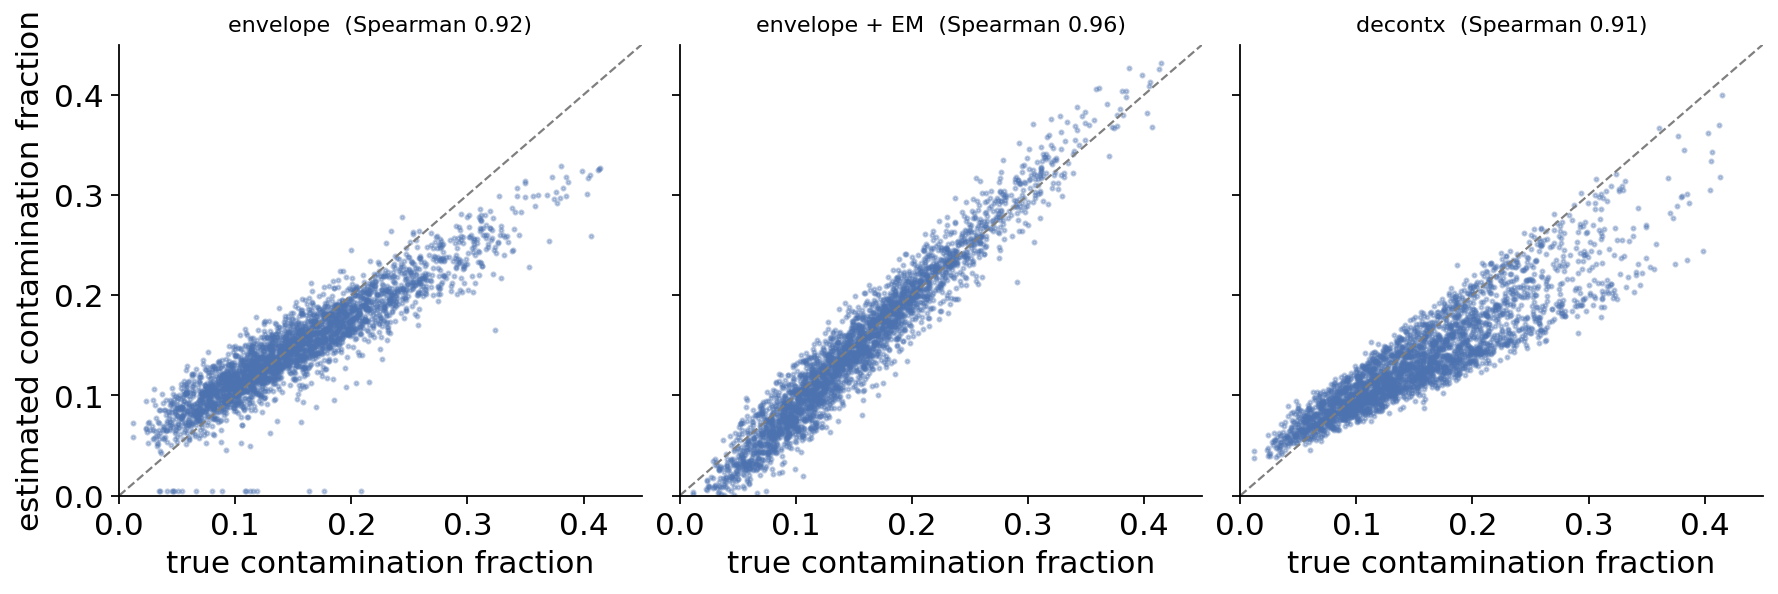

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharex=True, sharey=True,
                         constrained_layout=True)
truth = cells.obs['true_rho'].to_numpy()
for ax, name in zip(axes, ['envelope', 'envelope + EM', 'decontx']):
    est = runs[name].obs['ambient_contamination'].to_numpy()
    ax.scatter(truth, est, s=3, alpha=0.35, color='#4C72B0', rasterized=True)
    ax.plot([0, 0.5], [0, 0.5], ls='--', lw=1, color='#7f7f7f')
    ax.set_title(f'{name}  (Spearman {spearmanr(truth, est)[0]:.2f})', fontsize=10)
    ax.set_xlabel('true contamination fraction')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('estimated contamination fraction')
axes[0].set_xlim(0, 0.45); axes[0].set_ylim(0, 0.45)
plt.show()

How to read this:

* **Level.** The envelope's mean $\hat\rho$ sits within a few percent of the
  true 0.153, with no marker genes, no cluster labels and only ~30-UMI empty
  droplets. FastCAR, which assumes one soup for all three preparations,
  over-estimates and does not rank the cells at all (Spearman ≈ 0.1), and its
  correction ends up slightly *worse* than doing nothing.
* **Rank.** Per-cell ranking is good (Spearman ≈ 0.9). The constrained EM
  sharpens it further without moving the level, which is what it is for.
* **Gap closed.** The envelope closes about half of the distance to the true
  native counts. The remainder is mostly irreducible: subtracting the
  *expected* ambient counts cannot remove the Poisson noise of the actual
  ambient draw. DecontX ranks the cells well when it is handed the true
  populations, but under-estimates the level and closes less of the gap.

### 7.5 `level_shrink`: a deliberate, documented compromise

The raw lower-envelope estimate runs **above** the truth: the panel genes
still carry a little native expression, and that is read as soup. By
default the estimate is therefore multiplied by `level_shrink=0.75`. The
docstring is explicit that this is a trade-off, not a bias correction:
when the per-cell shape is imperfect, a slightly conservative subtraction
removes less native signal than it leaves soup behind. `level_shrink=1.0`
gives the unscaled estimate.

In [8]:
ad_honest = ov.pp.ambient.remove_ambient(cells.copy(), method='envelope', raw=raw,
                                         batch_key='prep', level_shrink=1.0)
pd.DataFrame([score(ad_env, 'level_shrink=0.75 (default)'),
              score(ad_honest, 'level_shrink=1.0')]).round(3)

                             mean rho_hat  Spearman vs true rho  gap closed
level_shrink=0.75 (default)         0.148                 0.922       0.510
level_shrink=1.0                    0.198                 0.922       0.482

Here the unscaled estimate is about 30 % too high and closes less of the
gap, so the default 0.75 is the better choice on this simulation. The ranking
is identical, since scaling does not change the order. Do not treat 0.75 as
universal: when you have an external check (spike-in, species mixing,
a negative-marker audit as in section 4.1), use it to decide.

### 7.6 Pitfall: `raw` must be the unfiltered matrix of the *same* run

Empty droplets are defined as "raw barcodes that are not called cells". If
`raw` comes from another run, or its barcodes are formatted differently (a
missing `-1` suffix, a sample prefix added by a merge), *no* called cell is
found in it. Every raw row, cells included, would then be treated as an
empty droplet, and the "soup" would silently become the cells' own
expression profile. `envelope` refuses such a pair instead:

In [9]:
raw_renamed = raw.copy()
raw_renamed.obs_names = [f'{b}-1' for b in raw.obs_names]   # e.g. a different barcode format
try:
    ov.pp.ambient.remove_ambient(cells.copy(), method='envelope',
                                 raw=raw_renamed, batch_key='prep')
except ValueError as err:
    print('refused:', str(err)[:260], '...')

refused: method='envelope': none of the called cells' barcodes (adata.obs_names, e.g. ['prep0_cell0000', 'prep0_cell0001']) occur in raw.obs_names (e.g. ['prep0_cell0000-1', 'prep0_cell0001-1']). raw must be the unfiltered matrix of the SAME run, containing the called  ...


The fix is to harmonise the barcodes (or load the matching raw matrix),
not to drop the check. Two related guards: if only *some* called cells are
missing from `raw`, you get a warning with the count; and genes are matched
**by name**, so a raw matrix that lists the same genes in another order is
re-ordered for you (a gene of `adata` absent from `raw` raises).

In [10]:
shuffled = raw[:, list(reversed(raw.var_names))].copy()   # same genes, reversed order
a_shuf = ov.pp.ambient.remove_ambient(cells.copy(), method='envelope',
                                      raw=shuffled, batch_key='prep')
print('identical result with reordered raw genes:',
      np.array_equal(a_shuf.X.toarray(), ad_env.X.toarray()))

identical result with reordered raw genes: True


### 7.7 Real data: what the envelope needs from the empty droplets

We now return to the human-mouse species-mixing data of section 5, where
the cross-species read fraction is a label-free measure of the soup. It is a
**single** preparation with perfect anchors (mouse genes are truly absent
from human cells), which is the opposite of the case the envelope targets.
It is still instructive.

In [11]:
hg_cells, hg_raw = ov.datasets.hgmm_mixture(raw_droplets=True)
genome = hg_cells.var['genome'].to_numpy()

def cross_species(X):
    h = np.asarray(X[:, genome == 'hg19'].sum(axis=1)).ravel()
    m = np.asarray(X[:, genome == 'mm10'].sum(axis=1)).ravel()
    f = h / np.maximum(h + m, 1)
    return float(np.minimum(f, 1 - f).mean())

hg_env = ov.pp.ambient.remove_ambient(hg_cells.copy(), method='envelope', raw=hg_raw)
hg_sx = ov.pp.ambient.remove_ambient(hg_cells.copy(), method='soupx', raw=hg_raw)
pd.DataFrame({'mean cross-species fraction': {
                  'raw (no correction)': cross_species(hg_cells.X),
                  'envelope': cross_species(hg_env.X),
                  'soupx': cross_species(hg_sx.X)},
              'mean rho_hat': {'raw (no correction)': np.nan,
                  'envelope': hg_env.obs['ambient_contamination'].mean(),
                  'soupx': hg_sx.obs['ambient_contamination'].mean()}}).round(4)

🔍 Downloading data to ./data/hgmm_mixture_cells.h5ad
⚠️ File ./data/hgmm_mixture_cells.h5ad already exists


🔍 Downloading data to ./data/hgmm_mixture_raw.h5ad
⚠️ File ./data/hgmm_mixture_raw.h5ad already exists


                     mean cross-species fraction  mean rho_hat
raw (no correction)                       0.0075           NaN
envelope                                  0.0074         0.005
soupx                                     0.0042         0.100

In [12]:
print('envelope rho_hat quantiles:',
      np.round(np.quantile(hg_env.obs['ambient_contamination'], [0, 0.5, 1]), 4))

envelope rho_hat quantiles: [0.005 0.005 0.005]


Here the envelope barely moves the cross-species fraction, and every cell's
$\hat\rho$ equals 0.005, the estimator's lower clip (`rho_lo`). A
collapsed, constant $\hat\rho$ is the signature of a **degenerate panel**.
We can see why with plain NumPy: rebuild the soup from the empty droplets,
take the genes the estimator may use for a panel (soup abundance above the
45th percentile, its `soup_floor_q`), and ask how many of them the human
cells never contain, and how many ambient counts they would carry at a
plausible contamination level.

In [13]:
called = hg_raw.obs_names.isin(hg_cells.obs_names)
soup_umi = np.asarray(hg_raw.X[~called].sum(axis=0)).ravel()
soup_prof = soup_umi / soup_umi.sum()
eligible = soup_prof >= np.quantile(soup_prof[soup_prof > 0], 0.45)

human = (hg_cells.obs['species'] == 'human').to_numpy()
human_counts = np.asarray(hg_cells.X[human].sum(axis=0)).ravel()
zero = eligible & (human_counts == 0)
expected_1pct = soup_prof * human_counts.sum() * 0.01   # ambient counts if rho were 1 %
print(f'{(~called).sum()} empty droplets, {eligible.sum()} panel-eligible soup genes')
print(f'{zero.sum()} of them have zero counts in all {human.sum()} human cells '
      f'(genomes: {dict(zip(*np.unique(genome[zero], return_counts=True)))})')
print(f'expected ambient counts per such gene at rho = 1 %: '
      f'median {np.median(expected_1pct[zero]):.1f}, max {expected_1pct[zero].max():.1f}')
print(f'chance of observing zero for the median gene: {np.exp(-np.median(expected_1pct[zero])):.2f}')

6000 empty droplets, 10548 panel-eligible soup genes
499 of them have zero counts in all 495 human cells (genomes: {'mm10': 499})
expected ambient counts per such gene at rho = 1 %: median 2.6, max 9.6
chance of observing zero for the median gene: 0.08


About 500 eligible soup genes, all mouse, are never seen in a human cell,
although at a contamination of only 1 % each should contribute a few
ambient counts to the human population (a zero for the median gene is an 8 %
event). Two things combine. First, the soup measured in these empty
droplets is not exactly the soup that ends up inside the cells: some genes
are over-represented in the empties. Second, the lower envelope ranks
~10,500 genes by their observed native-to-soup ratio and keeps the ~50
lowest, and the minimum of many noisy ratios is biased downward. So it
picks exactly these zero-count genes, observes no ambient counts on them,
and concludes $\rho \approx 0$. The failure needs **low contamination**
(here ~1 %, so expected counts per panel gene are small) and a **large pool
of truly absent genes** to select from. The simulated data above (15 %
contamination, every gene expressed everywhere) is the opposite regime, and
there the panel works.

SoupX, in contrast, is built for this case: it uses the absent genes as
its anchor and removes almost half of the cross-species reads.

**Practical check before trusting an envelope run:** look at
`obs['ambient_contamination']`. If most cells sit at 0.005 (the lower clip)
or at 0.9 (the upper clip), the panel is degenerate. Then inspect the soup
profile for genes absent from the cells, and prefer SoupX / FastCAR on
single-preparation data with clean anchors.

### 7.8 Where `envelope` fits among the methods

| Method | Needs | Use it when | Watch out for |
|---|---|---|---|
| **envelope** | raw matrix of the same run + empty droplets; `batch_key` for several preparations | pooled preparations with different soups, shallow empties, **no population-private gene** (SoupX: *No plausible marker genes found*) | `raw` must share barcodes with the cells; a constant $\hat\rho$ at the 0.005 / 0.9 clip means a degenerate panel; `level_shrink=0.75` is a deliberate, conservative default |
| **soupx** | raw matrix + empty droplets | one preparation with clear marker anchors | stops when no marker gene is absent anywhere |
| **decontx** | clustered filtered matrix | no empty droplets available | level depends on the clustering |
| **fastcar** | raw matrix + empty droplets | one homogeneous soup | one soup for all preparations mis-corrects pooled data |

Options worth knowing:

* `cluster_key=` uses your own labels as lineages instead of the internal
  PCA + k-means (`panel_lineage_k=20`). Prefer coarse labels: the panels
  want few, well-populated lineage × preparation groups.
* `use_em=True` refines per-cell ranking. It is off by default because, on
  data with a sub-1 % rare state, the EM can move contamination away from
  cells absorbed into a large cluster; read the `refine_rho_em` docstring
  before switching it on.
* `protect_outliers=True` damps the subtraction for (cell, gene) pairs in
  the extreme upper tail of that gene across all cells, i.e. counts the soup
  cannot explain (weak markers of a rare state), and moves the removal onto
  the cell's other genes.
* `ov.pp.ambient.estimate_contamination(adata, method='envelope', raw=raw)`
  gives the per-cell estimate without touching the counts.

### References

* Young, M. D. & Behjati, S. SoupX removes ambient RNA contamination from
  droplet-based single-cell RNA sequencing data. *GigaScience* 9, giaa151
  (2020). https://doi.org/10.1093/gigascience/giaa151
* Yang, S. *et al.* Decontamination of ambient RNA in single-cell RNA-seq
  with DecontX. *Genome Biology* 21, 57 (2020).
  https://doi.org/10.1186/s13059-020-1950-6
* Fleming, S. J. *et al.* Unsupervised removal of systematic background
  noise from droplet-based single-cell experiments using CellBender.
  *Nature Methods* 20, 1323–1335 (2023).
  https://doi.org/10.1038/s41592-023-01943-7
* Janssen, P. *et al.* The effect of background noise and its removal on
  the analysis of single-cell expression data. *Genome Biology* 24, 140
  (2023). https://doi.org/10.1186/s13059-023-02978-x
* Efron, B. & Morris, C. Stein's estimation rule and its competitors: an
  empirical Bayes approach. *JASA* 68, 117–130 (1973).
  https://doi.org/10.1080/01621459.1973.10481350